In [3]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cell_data = ad.read_h5ad('merged_cell.h5ad')

In [ ]:
cell_data

>just checking the cell data...

In [ ]:
np.unique(cell_data.obs['leiden'])

<h1> subset immune cells from full dataset </h1>

In [ ]:
# get normalized count data from the "raw" slot of the anndata object
cell_data_raw = cell_data.raw.to_adata()
cell_data_raw.obsm = cell_data.obsm
cell_data = cell_data_raw

In [ ]:
np.unique(cell_data.obs['leiden'])

In [ ]:
# subset the anndata object to include only immune cells
immune = cell_data[
    cell_data.obs['leiden'].isin(
        ['BL', 'DCs', 'Macr', 'Mast cells', 'Neutrophils','TL']
        )
        ]

In [ ]:
immune.X.shape

>these are all genes

In [ ]:
# cells in each
cell_counts = pd.crosstab(immune.obs['leiden'], immune.obs['condition'])
print(cell_counts)

<h2> differential expression across cell types </h2>

In [ ]:
# get the cluster names and define the three pairwise contrasts
clusters = (immune.obs['leiden'].cat.categories
            if pd.api.types.is_categorical_dtype(immune.obs['leiden'])
            else np.unique(immune.obs['leiden']))
pairs = [('mdx', 'WT'), ('mdx-TG', 'WT'), ('mdx-TG', 'mdx')]

# dictionary to collect the results
de_results = {}

for cl in clusters:
    ad = immune[immune.obs['leiden'] == cl].copy()
    for cond1, cond2 in pairs:
        sub = ad[ad.obs['condition'].isin([cond1, cond2])]
        counts = sub.obs['condition'].value_counts()
        # require at least a few cells in *each* of the two conditions
        if counts.get(cond1, 0) < 3 or counts.get(cond2, 0) < 3:
            continue
        sc.tl.rank_genes_groups(sub,
                                groupby='condition',
                                groups=[cond1],
                                reference=cond2,
                                method='wilcoxon')
        df = sc.get.rank_genes_groups_df(sub, group=cond1)
        key = f"{cl}_{cond1}_vs_{cond2}"
        de_results[key] = df

In [ ]:
# save all dataframes in an excel file (one sheet per contrast)
output_filename = 'DE_immune_cells.xlsx'

# Use ExcelWriter to save each DataFrame to a different sheet
with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:
    for name, df in de_results.items():
        df.to_excel(writer, sheet_name=name, index=False)

<h2> plotting </h2>

In [4]:
immune = ad.read_h5ad('immune.h5ad')

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

immune_cells = ['BL', 'Macr', 'Neutrophils','TL']
for cell in immune_cells:
    sc.pl.violin(immune[immune.obs['leiden'] == cell],
                 keys="COL3A1", 
                 groupby='condition', show=False, 
                 ax=axs[immune_cells.index(cell) // 2, immune_cells.index(cell) % 2])

plt.tight_layout()
plt.show()

<h3> unique genes </h3>

* try to plot heatmap of unique genes per group
* first get the unique genes and filter

In [ ]:
immune_subset = immune[immune.obs['leiden'].isin(['BL', 'Macr', 'TL'])].copy()

>only B cells, T cells and macrophages are in all datasets

In [ ]:
clusters = (immune_subset.obs['leiden'].cat.categories
            if pd.api.types.is_categorical_dtype(immune_subset.obs['leiden'])
            else np.unique(immune_subset.obs['leiden']))

contrast_group = ['WT', 'mdx', 'mdx-TG']

# dictionary to collect the results
de_results = {}

for cl in clusters:
    ad = immune_subset[immune_subset.obs['leiden'] == cl].copy()
    for contrast in contrast_group:
        sc.tl.rank_genes_groups(ad,
                                groupby='condition',
                                groups=[contrast],
                                reference='rest',
                                method='wilcoxon')
        df = sc.get.rank_genes_groups_df(ad, group=contrast)
        key = f"{cl}_{contrast}_vs_rest"
        de_results[key] = df

>differential expression tables reusing the code from earlier but specified for genes in one group versus the rest

In [ ]:
output_filename = 'immune_DE/unique genes.xlsx'

# Use ExcelWriter to save each DataFrame to a different sheet
with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:
    for name, df in de_results.items():
        df.to_excel(writer, sheet_name=name, index=False)

* the number of cells between groups is very different
* relying on DE isn't great
* this is very evident with violin plots
* heatmap visualization also shows this issue

In [3]:
# create a new column that combines cluster and condition for dotplot
immune.obs['cell_condition'] = immune.obs['leiden'].astype(str) + '_' + immune.obs['condition'].astype(str)

In [52]:
# genes related to immune fibrosis axis
genes = ['COL1A1', 'COL1A2', 'COL3A1', # ECM genes
         'TGFB1', # pro-fibrotic signaling genes
         'PDGFA', 'PDGFB', 'PDGFC', # pro-fibrotic fibroblast markers
         'LGALS3', 'FABP5', 'SPP1', 'TREM2', 'THBS1', 'GPNMB', # pro-fibrotic macrophage markers
         'LGMN', 'CTSS', 'CTSL', 'MMP19'] # ECM remodeling proteases

In [6]:
import matplotlib.pyplot as plt

In [34]:
# parameters for plotting
plt.rcParams['font.size'] = 8
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['svg.fonttype'] = 'none'

In [ ]:
# order the plotting categories by cluster and condition
print(immune.obs['cell_condition'].cat.categories)

Index(['BL_WT', 'BL_mdx', 'BL_mdx-TG', 'DCs_WT', 'Macr_WT', 'Macr_mdx',
       'Macr_mdx-TG', 'Mast cells_mdx-TG', 'Neutrophils_mdx',
       'Neutrophils_mdx-TG', 'TL_WT', 'TL_mdx', 'TL_mdx-TG'],
      dtype='object')


In [27]:
new_order = ['BL_WT', 'BL_mdx', 'BL_mdx-TG', 
             'TL_WT', 'TL_mdx', 'TL_mdx-TG',
             'Macr_WT', 'Macr_mdx','Macr_mdx-TG', 
             'Neutrophils_mdx', 'Neutrophils_mdx-TG','DCs_WT', 'Mast cells_mdx-TG']

immune.obs['cell_condition'] = immune.obs['cell_condition'].cat.reorder_categories(new_order)

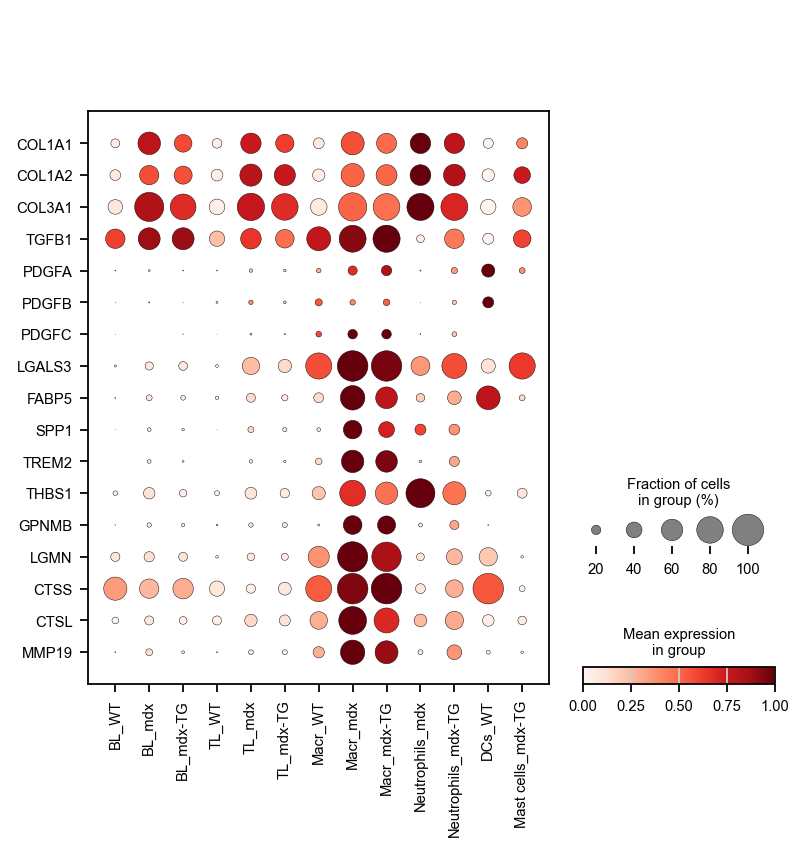

In [59]:
fig, axs = plt.subplots(figsize=(5.5, 5.5))

sc.pl.dotplot(
    immune,
    var_names=genes,
    groupby='cell_condition',
    standard_scale='var',
    cmap='Reds',
    swap_axes=True,
    show=False,
    ax=axs
)

# plt.show()

plt.savefig('Figures/immune_dotplot.svg', format='svg')

<h2> similarity metrics </h2>

In [60]:
sc.pp.highly_variable_genes(immune, n_top_genes=2000)
sc.pp.pca(immune)
sc.pp.neighbors(immune)
sc.tl.umap(immune)

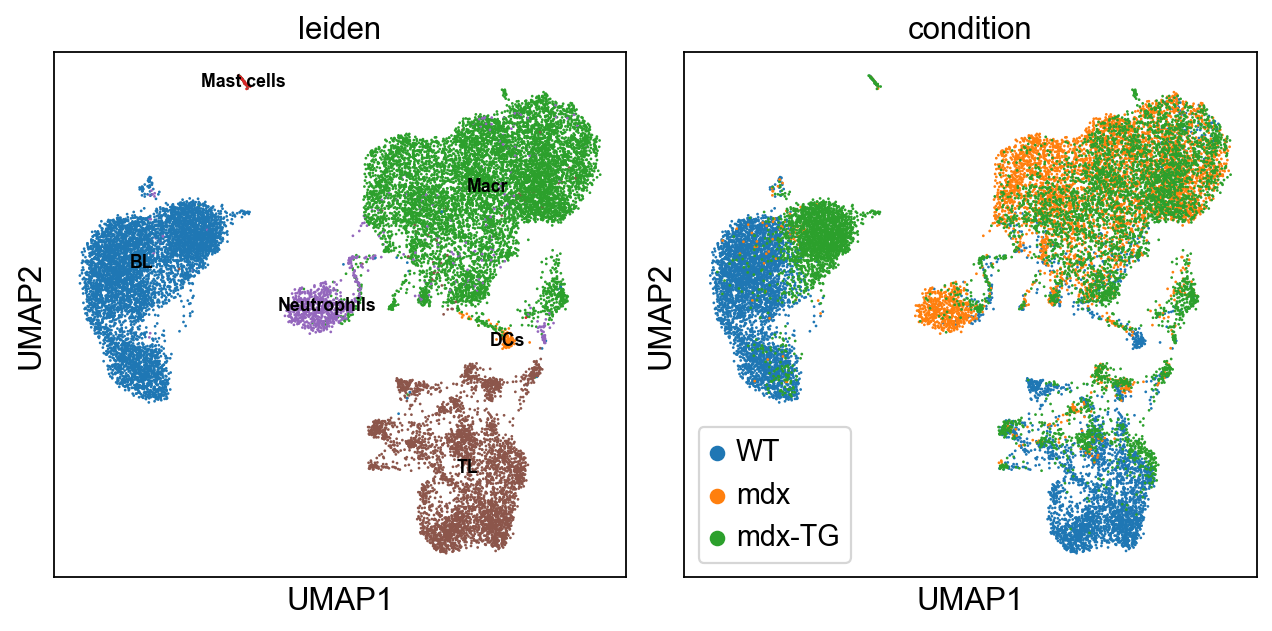

In [61]:
## visualize the UMAP colored by cluster and condition

# on the same figure, side by side
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

# plot based on cluster
sc.pl.umap(immune, color='leiden', legend_loc='on data', ax=axs[0], show=False)

# plot based on condition
# need to set show=False to avoid displaying the plot immediately, 
# since we're plotting on a specific axis
sc.pl.umap(immune, color='condition', legend_loc='lower left', ax=axs[1], show=False)

# adjust layout and show the figure
plt.tight_layout()
plt.show()

In [ ]:
# save immune cell anndata object for later use
immune.write_h5ad('immune.h5ad')

In [62]:
# load module for distance calculations
from scperturb import edist

In [ ]:
# store all results in a dictionary
edist_results = {}

for cell in immune_cells:

    # subset data per cell type
    ad_sub = immune[immune.obs['leiden'] == cell]

    # calculate the distance matrix grouped by genotype 
    mat = edist(ad_sub,
                obs_key='condition',
                dist='sqeuclidean',
                obsm_key='X_pca')
    
    # store it under the cell name
    edist_results[cell] = mat

In [ ]:
edist_results['Macr']

In [ ]:
# save to excel
output_filename = 'dist_immune_cells.xlsx'

# Use ExcelWriter to save each DataFrame to a different sheet
# set index=True to include the row labels (showing genotype label in the matrix) in the Excel file
with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:
    for name, df in edist_results.items():
        df.to_excel(writer, sheet_name=name, index=True)

<h2> gene scoring </h2>

In [ ]:
# muscle resident (from PMID: 37418531)
res = ['FOLR2', 'MT2', 'LYVE1', 'GAS6', 'FXYD2', 'FCGRT', 'MT1', 'CBR2', 'LTC4S', 'SELENOP']

# pro-inflammatory genes (from PMID: 31142802)
pro = ['CXCL9', 'NOS2', 'PTGS2', 'CXCL10', 'IL6', 'CCL5', 'DNASE1L3', 'SAA3', 'GBP4', 'ACOD1']

# anti-inflammatory genes (from PMID: 31142802)
anti = ['IL13RA2', 'CHIL3', 'PDCD1LG2', 'RETNLA', 'CCL11', 'RBP4', 'CISH', 'TMEM26', 'CHIL5', 'CHIL6']

# pro-fibrotic (from PMID: 37418531)
fibro = ['SPP1', 'FABP5', 'GPNMB', 'LGALS3', 'CTSD', 'CTSL', 'TREM2', 'SYNGR1', 'CXCL1', 'CTSS']

In [15]:
# macrophages = immune[immune.obs['leiden'] == 'Macr']
sc.tl.score_genes(macrophages, gene_list=res, score_name='res_score')
sc.tl.score_genes(macrophages, gene_list=pro, score_name='pro_score')
sc.tl.score_genes(macrophages, gene_list=anti, score_name='anti_score')
sc.tl.score_genes(macrophages, gene_list=fibro, score_name='fibro_score')

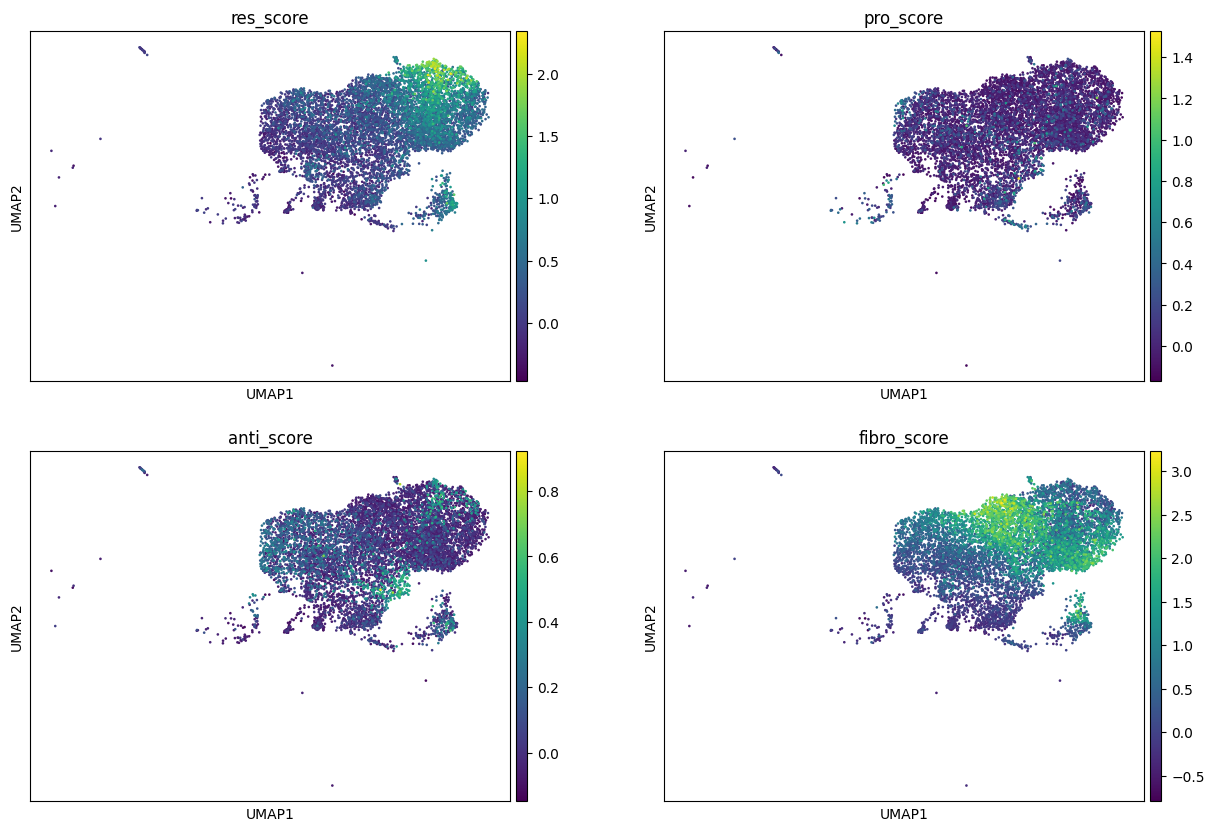

In [16]:
pathways = ['res_score', 'pro_score', 'anti_score', 'fibro_score']

fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for i, pathway in enumerate(pathways):
    row = i // 2
    col = i % 2
    sc.pl.umap(macrophages, color=pathway, cmap='viridis', show=False, ax=axs[row, col])

>min-max scale the scores...it's arbitary anyway

In [21]:
from sklearn.preprocessing import minmax_scale

In [ ]:
# scaling
for pathway in pathways:
    macrophages.obs[pathway] = minmax_scale(macrophages.obs[pathway])

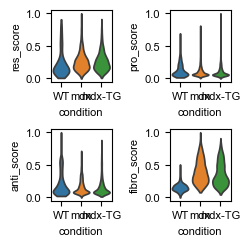

In [49]:
fig, axs = plt.subplots(2, 2, figsize=(2.5,2.5))

for pathway in pathways:
    sc.pl.violin(macrophages, 
                 keys=pathway,
                 stripplot=False,
                 groupby='condition', 
                 show=False, 
                 size=0,
                 ax=axs[pathways.index(pathway) // 2, pathways.index(pathway) % 2])
    
plt.tight_layout()
plt.savefig('Figures/macrophage_scores_violin.svg', format='svg', transparent=True, dpi=600)
plt.show()

In [30]:
res_score = macrophages.obs[['res_score', 'condition']]
pro_score = macrophages.obs[['pro_score', 'condition']]
anti_score = macrophages.obs[['anti_score', 'condition']]
fibro_score = macrophages.obs[['fibro_score', 'condition']]

In [ ]:
# save macrophage data for later use
macrophages.write_h5ad('macrophages.h5ad')

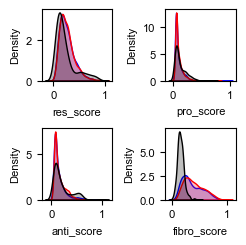

In [50]:
# colors to make it easier later
custom_colors = {
    'WT': '#000000', 
    'mdx': '#FF0000', 
    'mdx-TG': '#0000FF' 
}

fig, axs = plt.subplots(2, 2, figsize=(2.5,2.5))

sns.kdeplot(data=res_score, x='res_score', hue='condition', fill=True, common_norm=False, ax=axs[0,0], palette=custom_colors, legend=False)
sns.kdeplot(data=pro_score, x='pro_score', hue='condition', fill=True, common_norm=False, ax=axs[0,1], palette=custom_colors, legend=False)
sns.kdeplot(data=anti_score, x='anti_score', hue='condition', fill=True, common_norm=False, ax=axs[1,0], palette=custom_colors, legend=False)
sns.kdeplot(data=fibro_score, x='fibro_score', hue='condition', fill=True, common_norm=False, ax=axs[1,1], palette=custom_colors, legend=False)

plt.tight_layout()
plt.savefig('Figures/macrophage_scores_kde.svg', format='svg', dpi = 600)
plt.show()

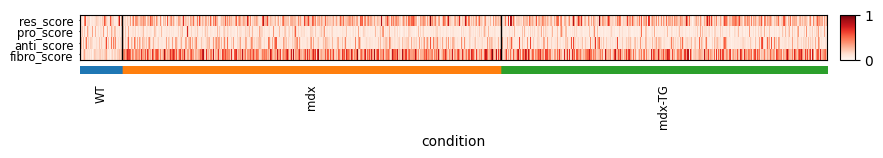

In [24]:
sc.pl.heatmap(macrophages, 
              var_names=pathways, 
              groupby='condition', 
              cmap='Reds', 
              swap_axes=True,
            #   standard_scale='var',
              show=True)